# Olist E-Commerce Analysis (Brazil, 2016-2018)

**Goal:** clean and merge the Olist tables, explore sales, customers, payments, delivery and reviews, then export a star schema for the Power BI dashboard.

**Table of contents**
1. Setup and data loading
2. Data understanding
3. Data preparation (payments, merge, missing values, dtypes)
4. Feature engineering (delivery KPIs)
5. Sanity checks and headline KPIs
6. Exploratory analysis
   - 6.1 Sales and revenue
   - 6.2 Customers and geography
   - 6.3 Products and pricing
   - 6.4 Payments
   - 6.5 Delivery and operations
   - 6.6 Reviews and satisfaction
7. Power BI export (star schema)



## 1. Setup and data loading

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

DATA_DIR = r"C:\Users\ayari\Downloads\E-commerce project\data\raw"   # folder that contains the Olist CSV files

In [43]:
orders      = pd.read_csv(f"{DATA_DIR}/olist_orders_dataset.csv")
order_items = pd.read_csv(f"{DATA_DIR}/olist_order_items_dataset.csv")
products    = pd.read_csv(f"{DATA_DIR}/olist_products_dataset.csv")
customers   = pd.read_csv(f"{DATA_DIR}/olist_customers_dataset.csv")
payments    = pd.read_csv(f"{DATA_DIR}/olist_order_payments_dataset.csv")
reviews     = pd.read_csv(f"{DATA_DIR}/olist_order_reviews_dataset.csv")
geolocation = pd.read_csv(f"{DATA_DIR}/olist_geolocation_dataset.csv")
sellers     = pd.read_csv(f"{DATA_DIR}/olist_sellers_dataset.csv")

## 2. Data understanding

In [44]:
# Column names of every table, to plan the joins
tables = {"orders": orders, "order_items": order_items, "products": products,
          "customers": customers, "payments": payments, "reviews": reviews,
          "geolocation": geolocation, "sellers": sellers}

for name, tbl in tables.items():
    print(name, tbl.shape)
    print(list(tbl.columns))
    print("-" * 50)

orders (99441, 8)
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
--------------------------------------------------
order_items (112650, 7)
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
--------------------------------------------------
products (32951, 9)
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
--------------------------------------------------
customers (99441, 5)
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
--------------------------------------------------
payments (103886, 5)
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']
-----

In [45]:
# Is order_id unique in each table? (unique count vs row count)
# Where they differ, a merge will duplicate rows (one order -> many items / payments / reviews)
for name in ["orders", "order_items", "payments", "reviews"]:
    tbl = tables[name]
    print(f"{name:12s} unique order_id: {tbl['order_id'].nunique():>7,} | rows: {len(tbl):>7,}")

orders       unique order_id:  99,441 | rows:  99,441
order_items  unique order_id:  98,666 | rows: 112,650
payments     unique order_id:  99,440 | rows: 103,886
reviews      unique order_id:  98,673 | rows:  99,224


## 3. Data preparation

### 3.1 Payments: one row per order
An order can have several payment rows (installments, vouchers). We collapse them: **sum** of value, **max** installments, **first** payment type.

In [46]:
payments_summary = (
    payments
    .groupby("order_id", as_index=False)
    .agg(
        payment_value=("payment_value", "sum"),
        payment_installments=("payment_installments", "max"),
        payment_type=("payment_type", "first"),
    )
)
payments_summary.head()

,order_id,payment_value,payment_installments,payment_type
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,2,credit_card
1,00018f77f2f0320c557190d7a144bdd3,259.83,3,credit_card
2,000229ec398224ef6ca0657da4fc703e,216.87,5,credit_card
3,00024acbcdf0a6daa1e931b038114c75,25.78,2,credit_card
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,3,credit_card


### 3.2 Master table
Left joins from `orders`, so orders without items, payments or reviews are kept (they get NaNs, handled below).

> **Heads-up:** this table is at **order-item level** (about 114K rows for about 99K orders). Order-level values such as `payment_value` are repeated on every item row, so **never sum `payment_value` on `df`**. Use `order_df` (section 4) instead.

In [47]:
df = (
    orders
    .merge(order_items,      on="order_id",    how="left")
    .merge(customers,        on="customer_id", how="left")
    .merge(products,         on="product_id",  how="left")
    .merge(payments_summary, on="order_id",    how="left")
    .merge(reviews,          on="order_id",    how="left")
)
print(df.shape)
df.info()

(114092, 35)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114092 entries, 0 to 114091
Data columns (total 35 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       114092 non-null  object 
 1   customer_id                    114092 non-null  object 
 2   order_status                   114092 non-null  object 
 3   order_purchase_timestamp       114092 non-null  object 
 4   order_approved_at              113930 non-null  object 
 5   order_delivered_carrier_date   112112 non-null  object 
 6   order_delivered_customer_date  110839 non-null  object 
 7   order_estimated_delivery_date  114092 non-null  object 
 8   order_item_id                  113314 non-null  float64
 9   product_id                     113314 non-null  object 
 10  seller_id                      113314 non-null  object 
 11  shipping_limit_date            113314 non-null  object 
 12  price            

### 3.3 Missing values

In [48]:
df.isna().sum()

order_id                              0
customer_id                           0
order_status                          0
order_purchase_timestamp              0
order_approved_at                   162
order_delivered_carrier_date       1980
order_delivered_customer_date      3253
order_estimated_delivery_date         0
order_item_id                       778
product_id                          778
seller_id                           778
shipping_limit_date                 778
price                               778
freight_value                       778
customer_unique_id                    0
customer_zip_code_prefix              0
customer_city                         0
customer_state                        0
product_category_name              2390
product_name_lenght                2390
product_description_lenght         2390
product_photos_qty                 2390
product_weight_g                    796
product_length_cm                   796
product_height_cm                   796


In [49]:
# Product info
df["product_category_name"] = df["product_category_name"].fillna("Unknown")

num_cols = ["product_name_lenght", "product_description_lenght", "product_photos_qty"]
df[num_cols] = df[num_cols].fillna(0)

size_cols = ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]
for col in size_cols:
    df[col] = df[col].fillna(df[col].median())

# Payments
df["payment_value"] = df["payment_value"].fillna(0)
df["payment_type"]  = df["payment_type"].fillna("not_defined")

# Review text
df["review_comment_title"]   = df["review_comment_title"].fillna("No Comment")
df["review_comment_message"] = df["review_comment_message"].fillna("No Comment")

df = df.copy()  # defragment

### 3.4 Data types

In [50]:
date_cols = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
    "review_creation_date", "review_answer_timestamp",
]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

## 4. Feature engineering

### 4.1 Order-level table (one row per order)
Use this one for anything about orders, payments, reviews or delivery.

In [51]:
order_df = (
    df[[
        "order_id", "customer_id", "customer_state",
        "order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date",
        "payment_value", "payment_installments", "payment_type", "review_score",
    ]]
    .drop_duplicates("order_id")
    .copy()
)

### 4.2 Delivery KPIs
- `delivery_time_days`: purchase -> delivered to customer
- `delay`: actual - estimated delivery date (**negative = early**)
- `is_late`: delivered after the estimated date

In [52]:
def create_delivery_features(data):
    data = data.copy()
    data["delivery_time_days"] = (data["order_delivered_customer_date"] - data["order_purchase_timestamp"]).dt.days
    data["delay"] = pd.to_timedelta(data["order_delivered_customer_date"] - data["order_estimated_delivery_date"])
    data["is_late"] = data["delay"] > pd.Timedelta(0)
    return data

order_df = create_delivery_features(order_df)
df       = create_delivery_features(df)

df["month_year"] = df["order_purchase_timestamp"].dt.to_period("M")

## 5. Sanity checks and headline KPIs

In [53]:
total_revenue = float(df["price"].sum())                       # product price only, freight excluded
unique_orders = order_df["order_id"].nunique()
AOV           = float(order_df["payment_value"].mean())        # order-level, correct
total_payments = float(payments["payment_value"].sum())        # [FIXED] source table, not the merged df

print(f"Unique orders        : {unique_orders:,}")
print(f"Total product revenue: R$ {total_revenue:,.2f}")
print(f"Total payments       : R$ {total_payments:,.2f}")
print(f"AOV                  : R$ {AOV:,.2f}")

Unique orders        : 99,441
Total product revenue: R$ 13,651,923.47
Total payments       : R$ 16,008,872.12
AOV                  : R$ 160.99


In [54]:
# [NEW] Order status mix: revenue above includes cancelled / unavailable orders unless filtered
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [55]:
# [NEW] customer_id is created per order. customer_unique_id identifies the real person.
print("customer_id        :", customers["customer_id"].nunique())
print("customer_unique_id :", customers["customer_unique_id"].nunique())

customer_id        : 99441
customer_unique_id : 96096


## 6. Exploratory analysis

### 6.1 Sales and revenue

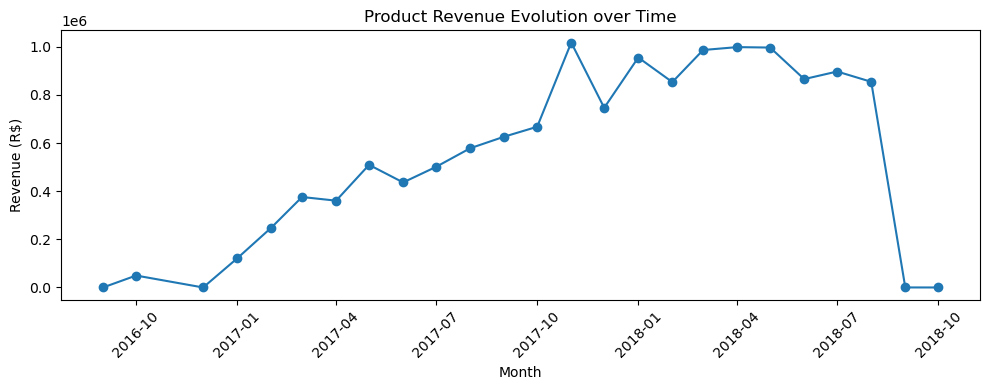

In [56]:
revenue_by_month = (
    df.groupby("month_year")["price"].sum().reset_index(name="revenue")
)
revenue_by_month["month_year"] = revenue_by_month["month_year"].dt.to_timestamp()

plt.figure(figsize=(10, 4))
plt.plot(revenue_by_month["month_year"], revenue_by_month["revenue"], marker="o")
plt.title("Product Revenue Evolution over Time")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [57]:
# Revenue and units per category
category_summary = (
    df.groupby("product_category_name")
    .agg(revenue=("price", "sum"), units_sold=("order_item_id", "count"))
    .reset_index()
)
category_summary["avg_unit_price"] = category_summary["revenue"] / category_summary["units_sold"]

top_categories_by_revenue  = category_summary.sort_values("revenue", ascending=False)
top_categories_by_quantity = category_summary.sort_values("units_sold", ascending=False)

top_categories_by_revenue.head(10)

,product_category_name,revenue,units_sold,avg_unit_price
12,beleza_saude,1263138.54,9727,129.859005
67,relogios_presentes,1206075.33,6001,200.979058
14,cama_mesa_banho,1050936.61,11270,93.250808
33,esporte_lazer,993656.51,8700,114.213392
45,informatica_acessorios,919640.54,7894,116.498675
55,moveis_decoracao,736282.47,8415,87.496431
27,cool_stuff,637258.51,3806,167.435236
73,utilidades_domesticas,634542.60,6989,90.791615
9,automotivo,594363.10,4256,139.652984
41,ferramentas_jardim,486432.45,4361,111.541493


In [58]:
top_categories_by_quantity.head(10)

,product_category_name,revenue,units_sold,avg_unit_price
14,cama_mesa_banho,1050936.61,11270,93.250808
12,beleza_saude,1263138.54,9727,129.859005
33,esporte_lazer,993656.51,8700,114.213392
55,moveis_decoracao,736282.47,8415,87.496431
45,informatica_acessorios,919640.54,7894,116.498675
73,utilidades_domesticas,634542.60,6989,90.791615
67,relogios_presentes,1206075.33,6001,200.979058
71,telefonia,323839.40,4550,71.173495
41,ferramentas_jardim,486432.45,4361,111.541493
9,automotivo,594363.10,4256,139.652984


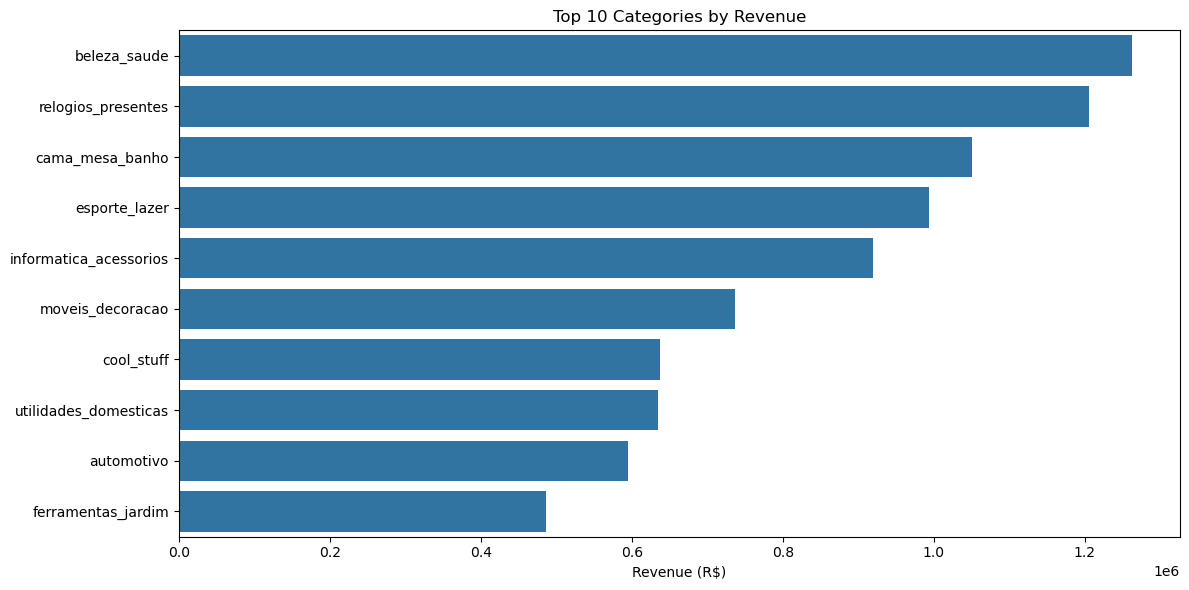

In [59]:
top10 = top_categories_by_revenue.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(data=top10, x="revenue", y="product_category_name")
plt.title("Top 10 Categories by Revenue")
plt.xlabel("Revenue (R$)")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 6.2 Customers and geography

In [60]:
state_summary = (
    df.groupby("customer_state")
    .agg(customers=("customer_id", "nunique"), revenue=("price", "sum"), freight=("freight_value", "sum"))
    .reset_index()
    .sort_values("revenue", ascending=False)
)
state_summary["revenue_share_%"] = (state_summary["revenue"] / state_summary["revenue"].sum() * 100).round(1)
state_summary

,customer_state,customers,revenue,freight,revenue_share_%
25,SP,41746,5228869.17,722620.00,38.3
18,RJ,12852,1831678.85,307397.43,13.4
10,MG,11635,1591518.47,272275.97,11.7
22,RS,5466,754250.33,136512.96,5.5
17,PR,5045,685911.51,118410.19,5.0
23,SC,3637,522120.11,90033.54,3.8
4,BA,3380,513182.78,100594.45,3.8
6,DF,2140,304658.17,51134.52,2.2
8,GO,2020,297535.49,53624.60,2.2
7,ES,2033,275910.68,50039.27,2.0


In [61]:
def plot_bar(x, y, title, x_label, y_label):
    """Plotly bar chart helper. Argument order: x values, y values, title, x label, y label."""
    return px.bar(x=x, y=y, labels={"x": x_label, "y": y_label}, title=title)

customers_state_sorted = state_summary.sort_values("customers", ascending=True)
fig = plot_bar(customers_state_sorted["customer_state"], customers_state_sorted["customers"],
               "Number of Customers by State", "customer_state", "number_of_customers")
fig.show()

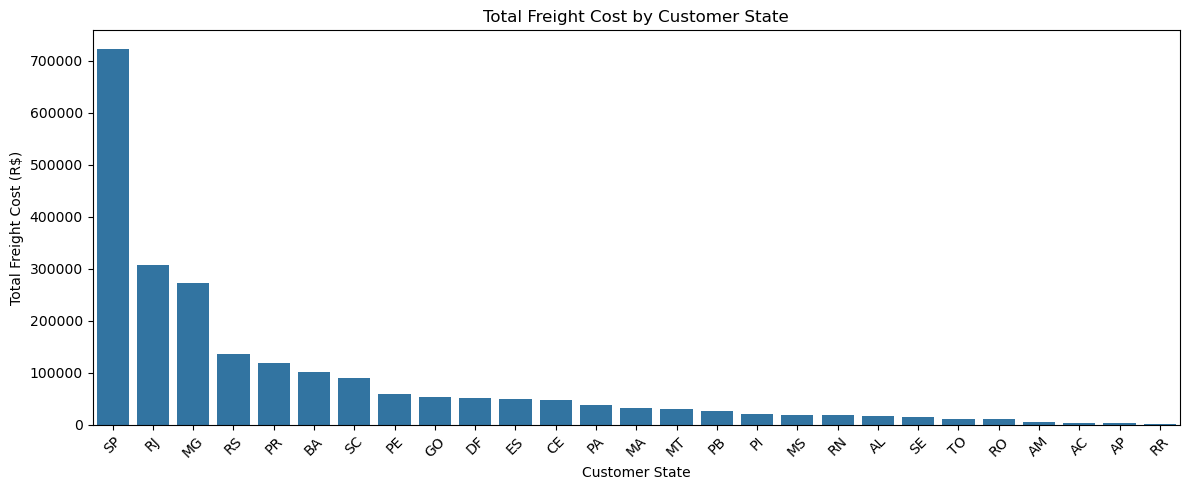

In [62]:
# Freight cost by state
freight_by_state = state_summary.sort_values("freight", ascending=False)

plt.figure(figsize=(12, 5))
sns.barplot(data=freight_by_state, x="customer_state", y="freight")
plt.title("Total Freight Cost by Customer State")
plt.xlabel("Customer State")
plt.ylabel("Total Freight Cost (R$)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 6.3 Products and pricing

In [63]:
product_prices = df.groupby("product_id")["price"]
most_expensive_products = product_prices.max().reset_index().sort_values("price", ascending=False)
cheapest_products       = product_prices.min().reset_index().sort_values("price", ascending=True)

display(most_expensive_products.head(10))
display(cheapest_products.head(10))

,product_id,price
9434,489ae2aa008f021502940f251d4cce7f,6735.00
13693,69c590f7ffc7bf8db97190b6cb6ed62e,6729.00
3698,1bdf5e6731585cf01aa8169c7028d6ad,6499.00
21316,a6492cc69376c469ab6f61d8f44de961,4799.00
25197,c3ed642d592594bb648ff4a04cee2747,4690.00
4967,259037a6a41845e455183f89c5035f18,4590.00
20782,a1beef8f3992dbd4cd8726796aa69c53,4399.87
14070,6cdf8fc1d741c76586d8b6b15e9eef30,4099.99
28494,dd113cb02b2af9c8e5787e8f1f0722f6,4059.00
13591,6902c1962dd19d540807d0ab8fade5c6,3999.90


,product_id,price
17767,8a3254bee785a526d548a81a9bc3c9be,0.85
5158,270516a3f41dc035aa87d220228f844c,1.20
700,05b515fdc76e888aada3c6d66c201dff,1.20
9238,46fce52cef5caa7cc225a5531c946c8b,2.20
6388,310dc32058903b6416c71faff132df9e,2.29
13461,680cc8535be7cc69544238c1d6a83fe8,2.90
6086,2e8316b31db34314f393806fd7b6e185,2.99
8965,44d53f1240d6332232e4393c06500475,3.00
5458,29781581fb82fe2389560a3a5331d0ee,3.06
3044,1716ea399ed8ee62ba811e6f55180f45,3.49


Correlation price vs quantity: -0.032


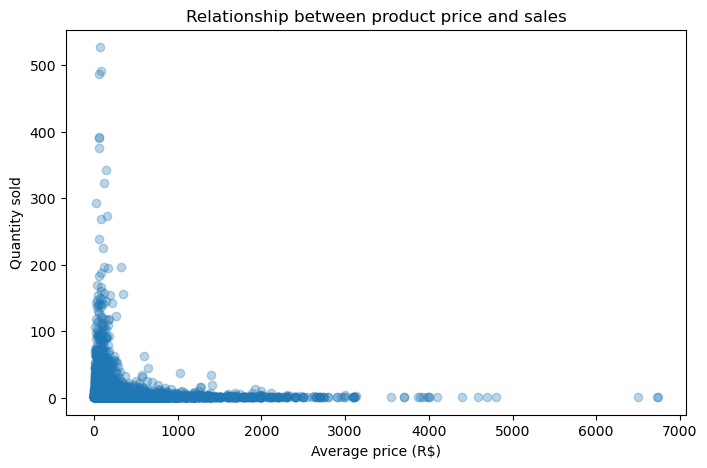

In [64]:
# Does a higher price mean fewer sales? (product level)
price_sales = (
    df.groupby("product_id")
    .agg(average_price=("price", "mean"), quantity_sold=("order_item_id", "count"))
    .reset_index()
)
print("Correlation price vs quantity:", round(price_sales["average_price"].corr(price_sales["quantity_sold"]), 3))

plt.figure(figsize=(8, 5))
plt.scatter(price_sales["average_price"], price_sales["quantity_sold"], alpha=0.3)
plt.xlabel("Average price (R$)")
plt.ylabel("Quantity sold")
plt.title("Relationship between product price and sales")
plt.show()

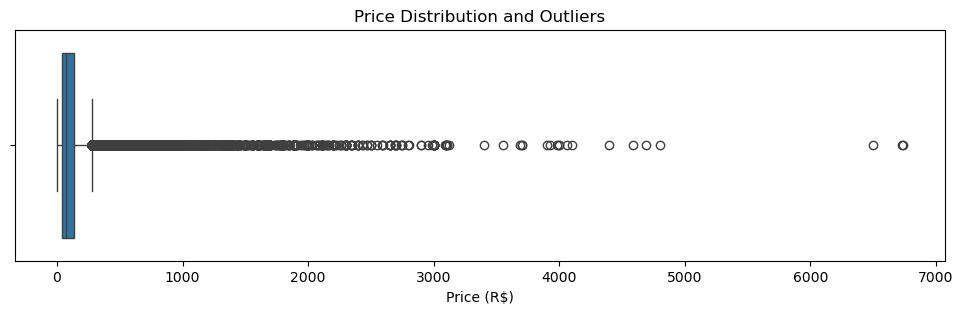

In [65]:
plt.figure(figsize=(12, 3))
sns.boxplot(data=df, x="price")
plt.xlabel("Price (R$)")
plt.title("Price Distribution and Outliers")
plt.show()

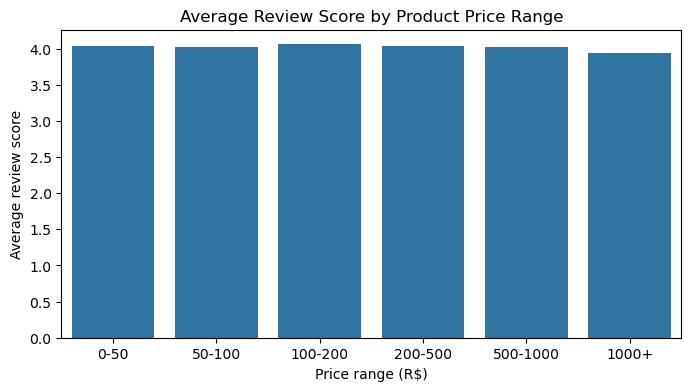

In [66]:
# Review score by price bucket
df["price_range"] = pd.cut(
    df["price"],
    bins=[0, 50, 100, 200, 500, 1000, float("inf")],
    labels=["0-50", "50-100", "100-200", "200-500", "500-1000", "1000+"],
)
price_review = df.groupby("price_range", observed=True)["review_score"].mean().reset_index()

plt.figure(figsize=(8, 4))
sns.barplot(data=price_review, x="price_range", y="review_score")
plt.xlabel("Price range (R$)")
plt.ylabel("Average review score")
plt.title("Average Review Score by Product Price Range")
plt.show()

### 6.4 Payments

In [67]:
payment_summary = (
    order_df.groupby("payment_type")
    .agg(orders=("order_id", "nunique"), avg_payment_value=("payment_value", "mean"), total_value=("payment_value", "sum"))
    .reset_index()
    .sort_values("orders", ascending=False)
)
payment_summary["order_share_%"] = (payment_summary["orders"] / payment_summary["orders"].sum() * 100).round(1)
payment_summary

,payment_type,orders,avg_payment_value,total_value,order_share_%
1,credit_card,75387,166.633472,12561997.58,75.8
0,boleto,19784,145.034435,2869361.27,19.9
4,voucher,2739,131.279109,359573.48,2.8
2,debit_card,1527,142.724158,217939.79,1.5
3,not_defined,4,0.000000,0.00,0.0


In [68]:
fig = plot_bar(payment_summary["payment_type"], payment_summary["orders"],
               "Orders by Payment Method", "payment_type", "number_of_orders")
fig.show()

In [69]:
# Average order value by number of installments
avg_order_value_by_installments = (
    order_df.groupby("payment_installments")["payment_value"]
    .agg(orders="count", average_order_value="mean")
    .reset_index()
)
avg_order_value_by_installments

,payment_installments,orders,average_order_value
0,0.0,2,94.315000
1,1.0,48268,121.037471
2,2.0,12363,129.124554
3,3.0,10429,144.362109
4,4.0,7070,165.060033
5,5.0,5227,184.888619
6,6.0,3908,211.594335
7,7.0,1622,189.335475
8,8.0,4251,309.774347
9,9.0,644,204.579534


### 6.5 Delivery and operations
Note the two different definitions below: the first function uses **delivered orders only** as the denominator for the late rate.

In [70]:
def calculate_delivery_metrics(data):
    delivered = data["delay"].notna()
    late      = data["delay"] > pd.Timedelta(0)
    on_time   = data["delay"] <= pd.Timedelta(0)
    return {
        "average_delivery_time_days": round(data["delivery_time_days"].mean(), 2),
        "late_orders_pct (delivered only)": round(late.sum() / delivered.sum() * 100, 2),
        "avg_delay_of_late_orders_days": round(float(data.loc[late, "delay"].dt.days.mean()), 2),
        "avg_review_late": round(float(data.loc[late, "review_score"].mean()), 2),
        "avg_review_on_time": round(float(data.loc[on_time, "review_score"].mean()), 2),
    }

delivery_metrics = calculate_delivery_metrics(order_df)
for k, v in delivery_metrics.items():
    print(f"{k:35s}: {v}")

average_delivery_time_days         : 12.09
late_orders_pct (delivered only)   : 8.11
avg_delay_of_late_orders_days      : 8.87
avg_review_late                    : 2.57
avg_review_on_time                 : 4.29


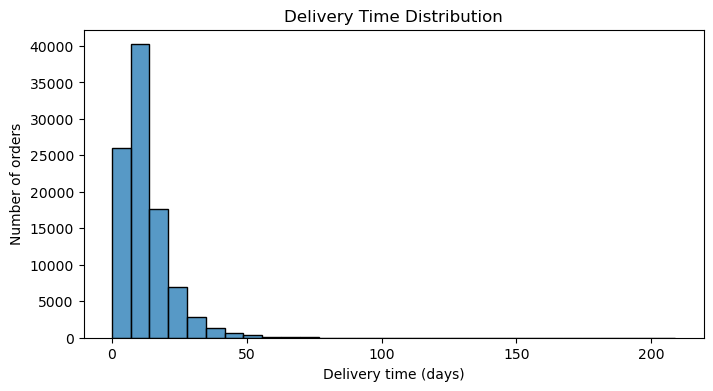

In [71]:
# Delivery time distribution
plt.figure(figsize=(8, 4))
sns.histplot(data=order_df, x="delivery_time_days", bins=30)
plt.xlabel("Delivery time (days)")
plt.ylabel("Number of orders")
plt.title("Delivery Time Distribution")
plt.show()

In [72]:
# Late vs on-time orders
late_vs_on_time = (
    order_df.dropna(subset=["delay"])
    .groupby("is_late")["order_id"].nunique()
    .reset_index(name="number_of_orders")
)
late_vs_on_time["delivery_status"] = late_vs_on_time["is_late"].map({True: "Late", False: "On_Time"})

fig = plot_bar(late_vs_on_time["delivery_status"], late_vs_on_time["number_of_orders"],
               "Late vs On-Time Orders", "delivery_status", "number_of_orders")   # [FIXED] x/y were swapped
fig.show()

In [73]:
# Average delivery time by state (slowest first)
average_delivery_time_by_state = (
    order_df.groupby("customer_state")["delivery_time_days"]
    .mean()
    .reset_index(name="average_delivery_days")
    .sort_values("average_delivery_days", ascending=False)
)
average_delivery_time_by_state

,customer_state,average_delivery_days
21,RR,28.975610
3,AP,26.731343
2,AM,25.986207
1,AL,24.040302
13,PA,23.316068
9,MA,21.117155
24,SE,21.029851
5,CE,20.817826
0,AC,20.637500
14,PB,19.953578


In [74]:
# [NEW] Late RATE by state. Counts alone just mirror order volume (SP has most orders, so most late orders)
late_rate_by_state = (
    order_df.dropna(subset=["delay"])
    .groupby("customer_state")
    .agg(delivered_orders=("order_id", "count"), late_orders=("is_late", "sum"))
    .reset_index()
)
late_rate_by_state["late_rate_%"] = (late_rate_by_state["late_orders"] / late_rate_by_state["delivered_orders"] * 100).round(1)
late_rate_by_state.sort_values("late_rate_%", ascending=False)

,customer_state,delivered_orders,late_orders,late_rate_%
1,AL,397,95,23.9
9,MA,717,141,19.7
16,PI,476,76,16.0
5,CE,1279,196,15.3
24,SE,335,51,15.2
4,BA,3256,457,14.0
18,RJ,12353,1664,13.5
26,TO,274,35,12.8
13,PA,946,117,12.4
7,ES,1995,244,12.2


In [75]:
# Sellers with the most late orders
sellers_delay = (
    df[df["is_late"]]
    .groupby("seller_id")["order_id"].nunique()
    .reset_index(name="late_orders")
    .sort_values("late_orders", ascending=False)
)
sellers_delay.head(10)

,seller_id,late_orders
401,4a3ca9315b744ce9f8e9374361493884,195
192,1f50f920176fa81dab994f9023523100,148
395,4869f7a5dfa277a7dca6462dcf3b52b2,130
1268,ea8482cd71df3c1969d7b9473ff13abc,118
553,6560211a19b47992c3666cc44a7e94c0,117
1105,cc419e0650a3c5ba77189a1882b7556a,101
1187,da8622b14eb17ae2831f4ac5b9dab84a,100
826,955fee9216a65b617aa5c0531780ce60,98
689,7c67e1448b00f6e969d365cea6b010ab,98
777,8b321bb669392f5163d04c59e235e066,97


### 6.6 Reviews and satisfaction

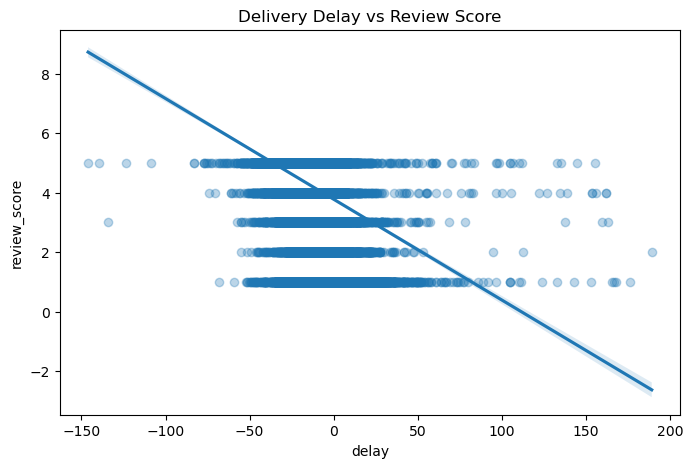

In [76]:
def plot_regression(data, x_col, y_col, title=None):
    """Scatter + regression line. Timedelta columns are converted to days first."""
    data = data.copy()
    for col in (x_col, y_col):
        if pd.api.types.is_timedelta64_dtype(data[col]):
            data[col] = data[col].dt.total_seconds() / 86400

    plt.figure(figsize=(8, 5))
    sns.regplot(data=data, x=x_col, y=y_col, scatter_kws={"alpha": 0.3})
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    if title:
        plt.title(title)
    plt.show()

# Delay (days vs estimate) vs review score
plot_regression(order_df.dropna(subset=["delay", "review_score"]), "delay", "review_score",
                "Delivery Delay vs Review Score")

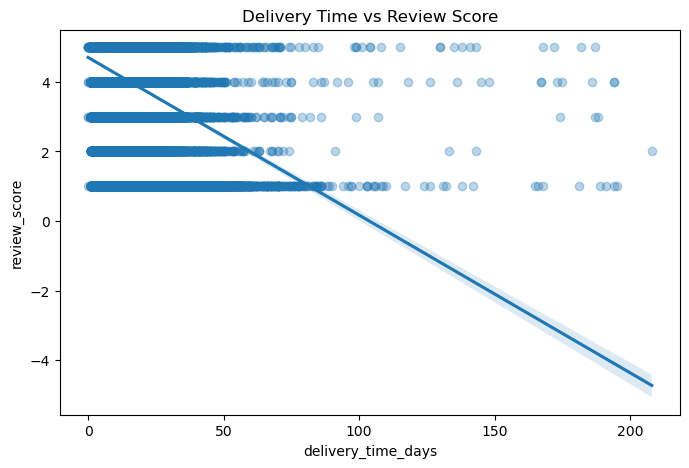

In [77]:
# Total delivery time vs review score
plot_regression(order_df.dropna(subset=["delivery_time_days", "review_score"]),
                "delivery_time_days", "review_score", "Delivery Time vs Review Score")

In [78]:
# [NEW] Review score distribution (matches the dashboard bar chart)
review_dist = reviews["review_score"].value_counts().sort_index()
print(review_dist)
print((review_dist / review_dist.sum() * 100).round(1))

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64
review_score
1    11.5
2     3.2
3     8.2
4    19.3
5    57.8
Name: count, dtype: float64


## 7. Power BI export (star schema)

| Table | Type | Grain |
|---|---|---|
| FactOrders | Fact | 1 row per order |
| FactOrderItems | Fact | 1 row per order line |
| DimCustomer | Dimension | 1 row per customer_id |
| DimProduct | Dimension | 1 row per product |
| DimSeller | Dimension | 1 row per seller |
| DimDate | Dimension | 1 row per calendar day |

In [79]:
# Power BI cannot load timedelta, so convert delay to numeric days
order_df["delay_days"] = order_df["delay"].dt.total_seconds() / 86400
order_df = order_df.drop(columns=["delay"])

FactOrders = order_df[[
    "order_id", "customer_id", "order_purchase_timestamp", "order_delivered_customer_date",
    "order_estimated_delivery_date", "payment_value", "payment_installments", "payment_type",
    "review_score", "delivery_time_days", "delay_days", "is_late",
]].copy()
FactOrders["order_purchase_timestamp"] = pd.to_datetime(FactOrders["order_purchase_timestamp"])
FactOrders["Date"] = FactOrders["order_purchase_timestamp"].dt.normalize()   # join key to DimDate

FactOrderItems = order_items[[
    "order_id", "order_item_id", "product_id", "seller_id", "shipping_limit_date", "price", "freight_value",
]].copy()

DimCustomer = customers[[
    "customer_id", "customer_unique_id", "customer_zip_code_prefix", "customer_city", "customer_state",
]].drop_duplicates("customer_id").copy()

DimProduct = products[[
    "product_id", "product_category_name", "product_name_lenght", "product_description_lenght",
    "product_photos_qty", "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm",
]].copy()

DimSeller = sellers[[
    "seller_id", "seller_zip_code_prefix", "seller_city", "seller_state",
]].drop_duplicates("seller_id").copy()

DimDate = pd.DataFrame({
    "Date": pd.date_range(FactOrders["order_purchase_timestamp"].min().date(),
                          FactOrders["order_purchase_timestamp"].max().date(), freq="D")
})
DimDate["Year"]         = DimDate["Date"].dt.year
DimDate["Month Number"] = DimDate["Date"].dt.month
DimDate["Month"]        = DimDate["Date"].dt.month_name()
DimDate["Quarter"]      = "Q" + DimDate["Date"].dt.quarter.astype(str)
DimDate["Year Month"]   = DimDate["Date"].dt.to_period("M").astype(str)

In [80]:
# Integrity checks (all should pass)
assert FactOrders["order_id"].is_unique, "Duplicate order_id in FactOrders"
assert set(DimCustomer["customer_id"]) == set(FactOrders["customer_id"]), "Customer/order mismatch"
print("FactOrders rows:", len(FactOrders), "| DimCustomer rows:", len(DimCustomer))
print("Customers with no order:", len(set(DimCustomer["customer_id"]) - set(FactOrders["customer_id"])))

FactOrders rows: 99441 | DimCustomer rows: 99441
Customers with no order: 0


In [81]:
exports = {
    "FactOrders": FactOrders, "FactOrderItems": FactOrderItems,
    "DimCustomer": DimCustomer, "DimProduct": DimProduct,
    "DimSeller": DimSeller, "DimDate": DimDate,
}
for name, table in exports.items():
    table.to_csv(f"{name}.csv", index=False)
print("Exported:", ", ".join(f"{n}.csv" for n in exports))

Exported: FactOrders.csv, FactOrderItems.csv, DimCustomer.csv, DimProduct.csv, DimSeller.csv, DimDate.csv
